# Computing overlap between two Ilastik models

# \*\*\* THIS IS FOR DEMONSTRATION OF THE LOGIC ONLY

- PLEASE USE `main.py` FOR ANALYSIS!!!!!!!!!!!!!!!!!

The goal of this code is to find the overlap between two Ilastik classification masks :) 

We will do this by following these steps: 
- Look at the relevant files in both folders and matching files 
- Look at the matched files and finding where the masks overlap 
- Computing the percentage of the overlap
- Returning the results in a nice format

# Libraries 

Lets load in the external code we will need on our journeys! 

In [51]:
import numpy as np					# Lets us do math gooder 
import matplotlib.pyplot as plt 	# Graphs 
import pandas as pd 				# Kind of like Excel for python 
import cv2							# Reads the image files
from pathlib import Path

# Open up the data

I put the data in the same directory as the code, but you don't have to! Just get the full folder location, or "Path", to the data and paste it here! 

In [52]:
path_to_data = Path("./PNN_PV")

## Run settings

Each time you run this notebook, all results are saved into **one new folder** (`results/<date>_<time>_<run_name>/`) along with a record of exactly which files and settings were used. Nothing from earlier runs is overwritten. Set a short `run_name` and the Method 2 thresholds here (the defaults mean "no filtering").

In [53]:
from datetime import datetime

# ---- Run settings: change these, then run the notebook top to bottom ----
run_name = "PNN-vs-PV"		# Short label for this run. It becomes part of the results folder name.
min_size_px = 0				# Method 2: ignore objects smaller than this many pixels (0 = keep everything)
min_frac_overlap = 0.0		# Method 2: fraction of an object that must be covered (0 = any shared pixel counts)

# Every run gets its own folder, so old results are never overwritten
run_dir = Path("./results") / f"{datetime.now():%Y-%m-%d_%H%M}_{run_name}"

## Grab the right data

First, lets grab all the file types we are interested in: 
- TIF (or TIFF) 
- CSV

In [54]:
file_formats = ["tiff", "tif", "csv"] 



## Index the folders

Each brain section has 4 files per stain (the mask, the raw image, a table and probabilities). The only one we want is the **mask**, which Ilastik saves as `<section>_<STAIN>_Object Predictions.tiff`.

We build a "dictionary" for each folder: the section ID (the filename with the stain and suffix chopped off) is the key, and the file's location is the value.

In [55]:
pnn_folder = path_to_data / "PFC_PNN_TrainingCrops"
pv_folder = path_to_data / "PFC_TrainingCrops"
mask_suffix = "Object Predictions.tiff"

def index_masks(folder, stain):
    """Return {section_id: path_to_mask} for every mask file in the folder."""
    ending = f"_{stain}_{mask_suffix}"
    return {f.name.removesuffix(ending): f
            for f in sorted(folder.iterdir())
            if f.name.endswith(ending)}

## Match the sections

Now we find the section IDs that show up in **both** folders. Anything that only shows up in one gets printed so nothing silently goes missing.

In [56]:
pnn_index = index_masks(pnn_folder, "PNN")
pv_index = index_masks(pv_folder, "PV")

# Only keep sections that exist in BOTH folders
matched_ids = sorted(set(pnn_index) & set(pv_index))

# Shout about anything that didn't find a partner
only_pnn = sorted(set(pnn_index) - set(pv_index))
only_pv = sorted(set(pv_index) - set(pnn_index))

print(f"PNN masks: {len(pnn_index)} | PV masks: {len(pv_index)} | Matched: {len(matched_ids)}")
if only_pnn: print("Only in PNN folder:", only_pnn)
if only_pv:  print("Only in PV folder:", only_pv)

pd.DataFrame({"section_id": matched_ids,
              "PNN_file": [pnn_index[s].name for s in matched_ids],
              "PV_file": [pv_index[s].name for s in matched_ids]})

PNN masks: 8 | PV masks: 8 | Matched: 8


,section_id,PNN_file,PV_file
0,MAX_15731_S1_S1_PFC_LR_4.4.oif,MAX_15731_S1_S1_PFC_LR_4.4.oif_PNN_Object Pred...,MAX_15731_S1_S1_PFC_LR_4.4.oif_PV_Object Predi...
1,MAX_15747_S1_S5_PFC_LR_2.8-2.0.oif,MAX_15747_S1_S5_PFC_LR_2.8-2.0.oif_PNN_Object ...,MAX_15747_S1_S5_PFC_LR_2.8-2.0.oif_PV_Object P...
2,MAX_15761_S1_S4_PFC_L_3.1_R_3.oif,MAX_15761_S1_S4_PFC_L_3.1_R_3.oif_PNN_Object P...,MAX_15761_S1_S4_PFC_L_3.1_R_3.oif_PV_Object Pr...
3,MAX_15764_S1_S2_PFC_4.0_L.oif,MAX_15764_S1_S2_PFC_4.0_L.oif_PNN_Object Predi...,MAX_15764_S1_S2_PFC_4.0_L.oif_PV_Object Predic...
4,MAX_16302_S1_S3_PFC_LR_3.6.oif,MAX_16302_S1_S3_PFC_LR_3.6.oif_PNN_Object Pred...,MAX_16302_S1_S3_PFC_LR_3.6.oif_PV_Object Predi...
5,MAX_16308_S1_S6_PFC_L_2.2_R_2.oif,MAX_16308_S1_S6_PFC_L_2.2_R_2.oif_PNN_Object P...,MAX_16308_S1_S6_PFC_L_2.2_R_2.oif_PV_Object Pr...
6,MAX_16317_S1_S1_PFC_R_4.4.oif,MAX_16317_S1_S1_PFC_R_4.4.oif_PNN_Object Predi...,MAX_16317_S1_S1_PFC_R_4.4.oif_PV_Object Predic...
7,MAX_16340_S1_S4_PFC_LR_-3.2.oif,MAX_16340_S1_S4_PFC_LR_-3.2.oif_PNN_Object Pre...,MAX_16340_S1_S4_PFC_LR_-3.2.oif_PV_Object Pred...


## Look at the masks

The masks are stored as 0s and 1s, which is basically black on black. So we turn every "1" pixel into white (255, 255, 255) to make it visible. PNN on the left, PV on the right.

In [57]:
def load_mask(path):
    """Read an Ilastik mask and return it as True/False (True = stained object)."""
    img = cv2.imread(str(path), cv2.IMREAD_UNCHANGED)
    return img > 0

def white_on_black(mask):
    """Turn a True/False mask into an RGB image where the '1' pixels are (255, 255, 255)."""
    rgb = np.zeros((*mask.shape, 3), dtype=np.uint8)
    rgb[mask] = (255, 255, 255)
    return rgb

pnn_masks = {sid: load_mask(p) for sid, p in pnn_index.items() if sid in matched_ids}
pv_masks  = {sid: load_mask(p) for sid, p in pv_index.items()  if sid in matched_ids}

# The two masks for a section must be the exact same size to compare them
for sid in matched_ids:
    assert pnn_masks[sid].shape == pv_masks[sid].shape, f"Shape mismatch in {sid}"

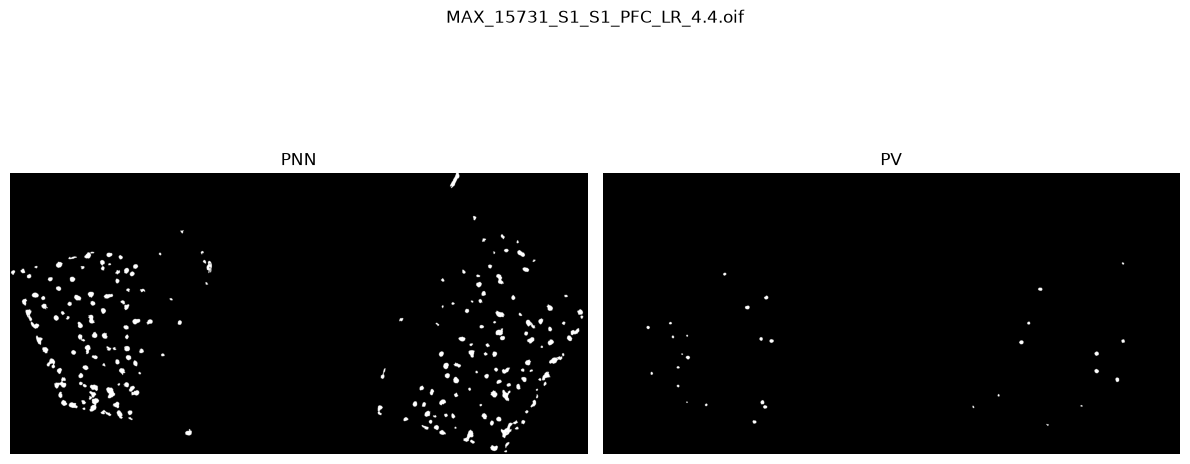

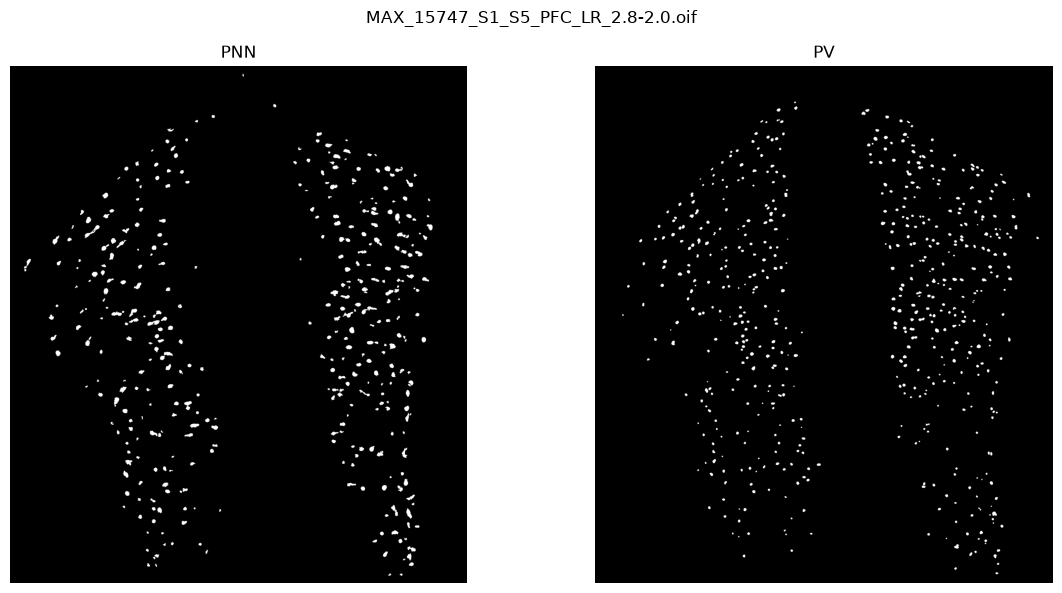

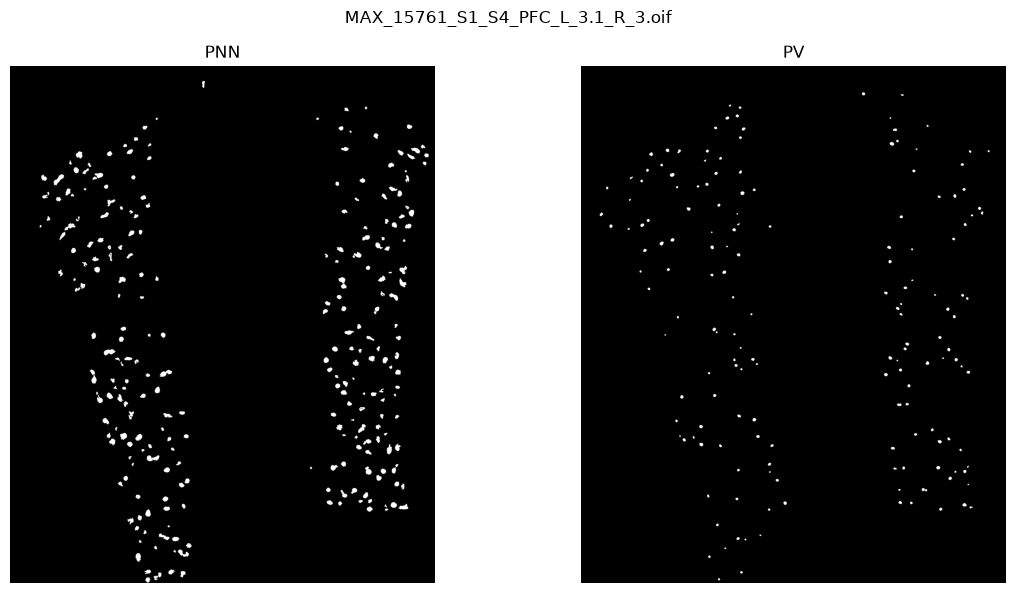

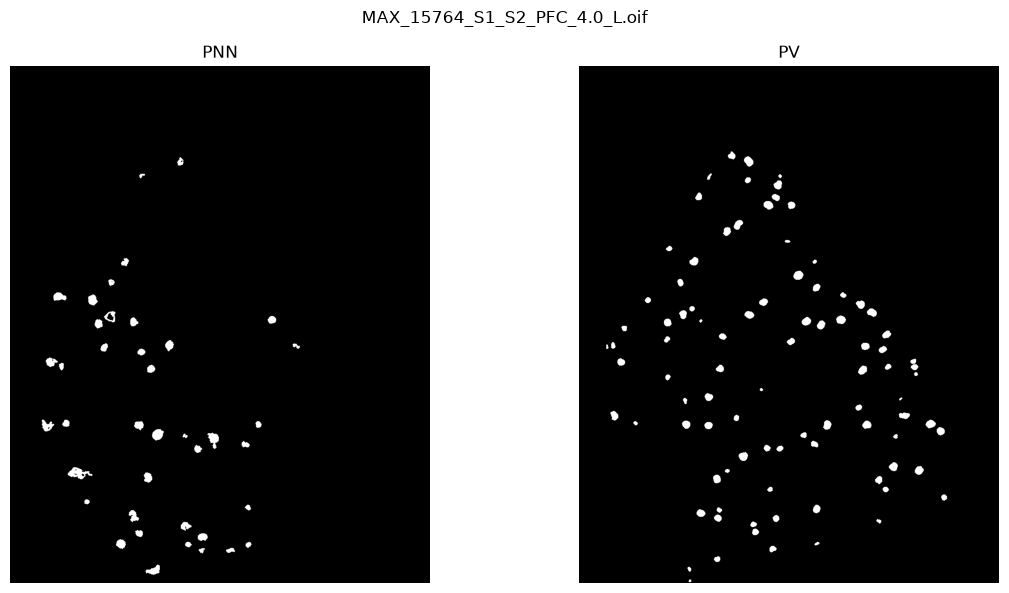

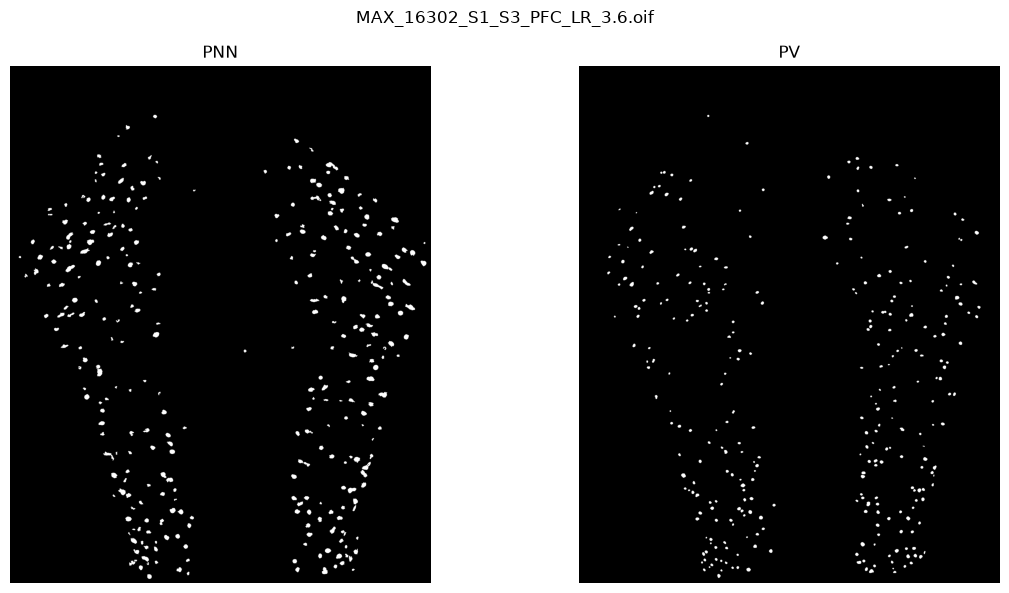

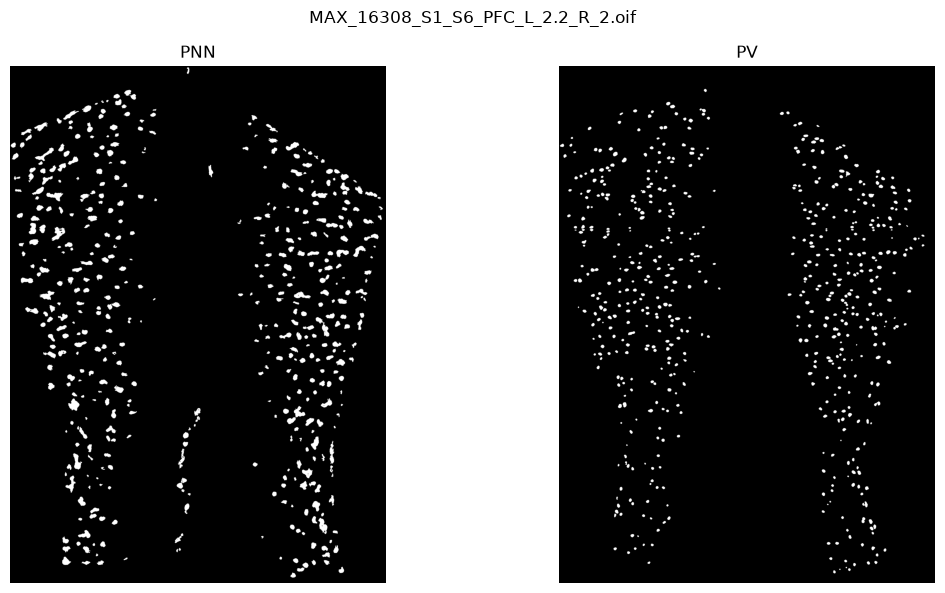

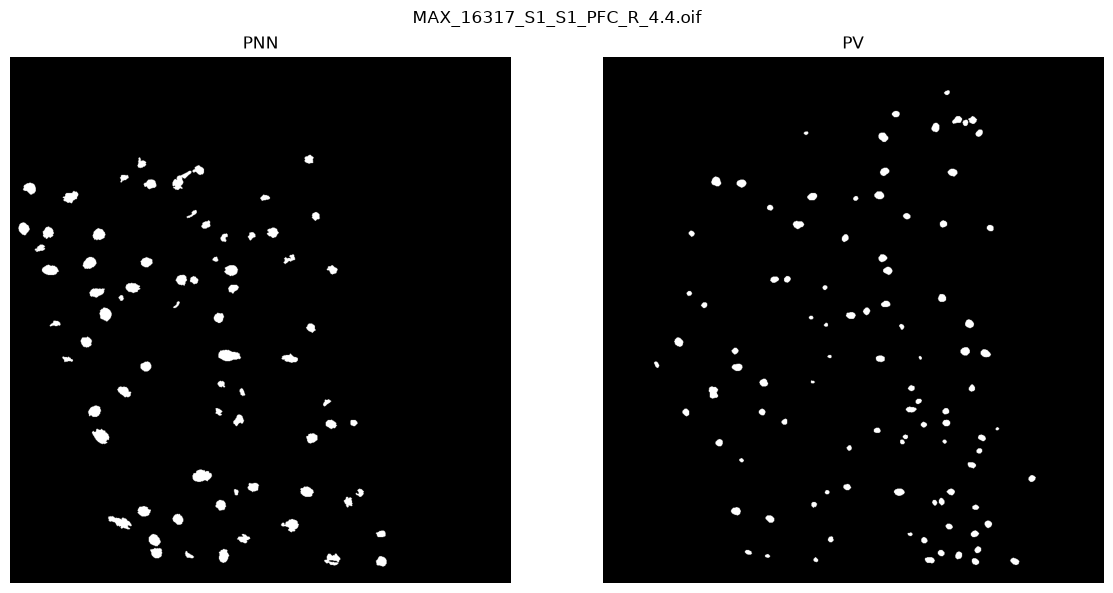

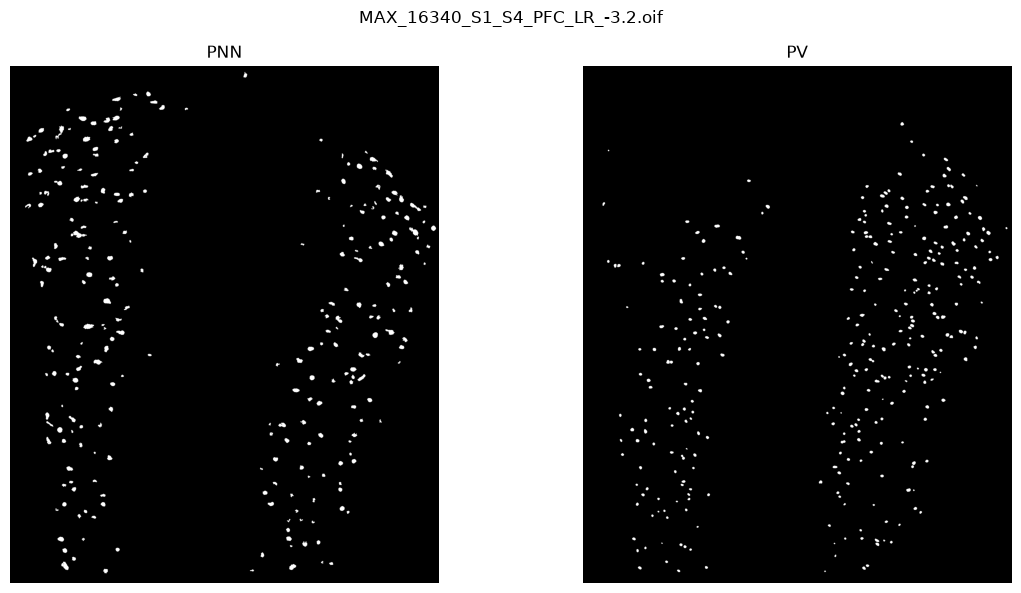

In [58]:
for section_id in matched_ids:
    fig, (ax_pnn, ax_pv) = plt.subplots(1, 2, figsize=(12, 6))
    ax_pnn.imshow(white_on_black(pnn_masks[section_id]))
    ax_pnn.set_title("PNN")
    ax_pv.imshow(white_on_black(pv_masks[section_id]))
    ax_pv.set_title("PV")
    for ax in (ax_pnn, ax_pv):
        ax.axis("off")
    fig.suptitle(section_id)
    plt.tight_layout()
    plt.show()

## Show the overlap

Now we lay both masks on top of each other, one color each:
- **Red** = PV (the base)
- **Green** = PNN
- **Yellow** = both (red + green), which is the overlap we care about

In [59]:
from matplotlib.patches import Patch

def overlap_image(pnn_mask, pv_mask):
    """PV (base) goes in the red channel, PNN in the green channel.
    Where both are on, red + green = yellow."""
    rgb = np.zeros((*pnn_mask.shape, 3), dtype=np.uint8)
    rgb[pv_mask, 0] = 255
    rgb[pnn_mask, 1] = 255
    return rgb

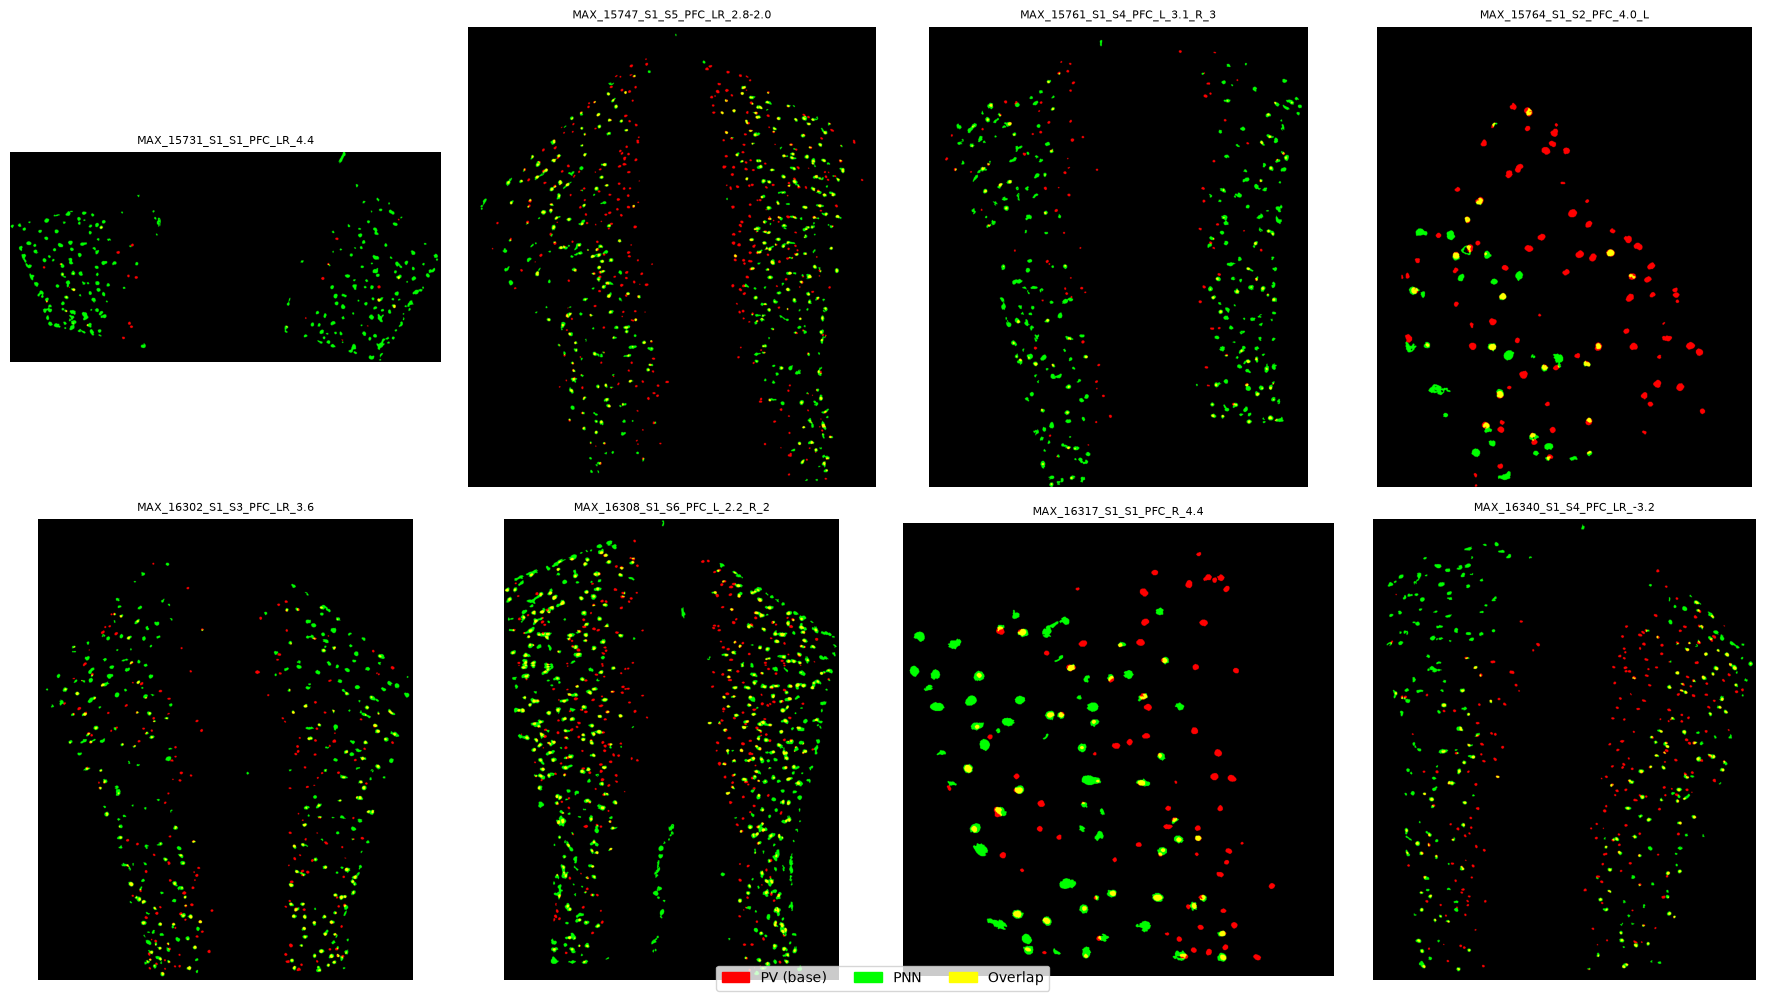

In [60]:
fig, axes = plt.subplots(2, 4, figsize=(18, 10))

for ax, section_id in zip(axes.flat, matched_ids):
    ax.imshow(overlap_image(pnn_masks[section_id], pv_masks[section_id]))
    ax.set_title(section_id.replace(".oif", ""), fontsize=8)
    ax.axis("off")

# Hide any unused panels
for ax in list(axes.flat)[len(matched_ids):]:
    ax.axis("off")

fig.legend(handles=[Patch(color="red", label="PV (base)"),
                    Patch(color="lime", label="PNN"),
                    Patch(color="yellow", label="Overlap")],
           loc="lower center", ncol=3)
plt.tight_layout()
plt.show()

# Method 1: total overlap

Treat each mask as one big blob and count pixels. For each brain section we report three percentages. Pick whichever answers your question:

| Column | What it means |
|---|---|
| `pct_PNN_covered_by_PV` | Of all the PNN-stained area, how much is also PV-stained? |
| `pct_PV_covered_by_PNN` | Of all the PV-stained area, how much is also PNN-stained? |
| `pct_of_combined_shared` | Of the area stained by *either* PNN or PV, how much is stained by *both*? |

The `_pixels` columns are the raw counts behind those percentages (`shared_pixels` = stained in both, `combined_pixels` = stained in either).

One row per section, saved as a single CSV for the whole batch.

In [61]:
def total_overlap(pnn_mask, pv_mask):
    """Pixel counts and overlap percentages for one pair of masks."""
    pnn_pixels = int(pnn_mask.sum())
    pv_pixels = int(pv_mask.sum())
    shared_pixels = int((pnn_mask & pv_mask).sum())			# stained in BOTH
    combined_pixels = pnn_pixels + pv_pixels - shared_pixels	# stained in EITHER
    return {
        "PNN_pixels": pnn_pixels,
        "PV_pixels": pv_pixels,
        "shared_pixels": shared_pixels,
        "combined_pixels": combined_pixels,
        "pct_PNN_covered_by_PV": 100 * shared_pixels / pnn_pixels if pnn_pixels else np.nan,
        "pct_PV_covered_by_PNN": 100 * shared_pixels / pv_pixels if pv_pixels else np.nan,
        "pct_of_combined_shared": 100 * shared_pixels / combined_pixels if combined_pixels else np.nan,
    }

summary = pd.DataFrame([{"section_id": sid, **total_overlap(pnn_masks[sid], pv_masks[sid])}
                        for sid in matched_ids])
summary

,section_id,PNN_pixels,PV_pixels,shared_pixels,combined_pixels,pct_PNN_covered_by_PV,pct_PV_covered_by_PNN,pct_of_combined_shared
0,MAX_15731_S1_S1_PFC_LR_4.4.oif,76817,4762,1751,79828,2.279443,36.770265,2.193466
1,MAX_15747_S1_S5_PFC_LR_2.8-2.0.oif,116812,85205,40341,161676,34.534979,47.345813,24.951755
2,MAX_15761_S1_S4_PFC_L_3.1_R_3.oif,81746,19288,9388,91646,11.484354,48.672750,10.243764
3,MAX_15764_S1_S2_PFC_4.0_L.oif,10303,16854,3272,23885,31.757740,19.413789,13.698974
4,MAX_16302_S1_S3_PFC_LR_3.6.oif,89947,42874,20725,112096,23.041347,48.339320,18.488617
5,MAX_16308_S1_S6_PFC_L_2.2_R_2.oif,194859,95691,57285,233265,29.398180,59.864564,24.557906
6,MAX_16317_S1_S1_PFC_R_4.4.oif,21389,13265,4645,30009,21.716770,35.016962,15.478690
7,MAX_16340_S1_S4_PFC_LR_-3.2.oif,66455,45040,17415,94080,26.205703,38.665631,18.510842


# Method 2: object-level overlap

The masks only say "stained or not", so first we find the individual objects by giving every separate blob its own number (8-connectivity). Then for **every object** of one stain we ask: how many of its pixels are covered by the other stain, and how many different partner objects does it touch?

This is done in both directions (PNN objects against PV, and PV objects against PNN). We save one CSV per section with every object, and a batch summary at the end.

In [62]:
def label_mask(mask):
    """Give every separate blob its own number (1, 2, 3...). 0 is background.
    connectivity=8 means pixels touching diagonally count as the same object."""
    return cv2.connectedComponentsWithStats(mask.astype(np.uint8), connectivity=8)

def object_overlap_table(section_id, stain, own, other_mask, other_labels):
    """One row per object in `own`, describing how much the other stain overlaps it."""
    n, labels, stats, centroids = own

    # Pixels where this stain AND the other stain are both on
    both = other_mask & (labels > 0)
    own_ids = labels[both]
    partner_ids = other_labels[both]

    # Overlapping pixels per object (index 0 is background, so drop it)
    overlap_px = np.bincount(own_ids, minlength=n)[1:]

    # How many different objects of the other stain does each object touch?
    pairs = np.unique(np.stack([own_ids, partner_ids]), axis=1)
    n_partners = np.bincount(pairs[0], minlength=n)[1:]

    size_px = stats[1:, cv2.CC_STAT_AREA]
    return pd.DataFrame({
        "section_id": section_id,
        "stain": stain,
        "object_id": np.arange(1, n),
        "size_px": size_px,
        "centroid_x": centroids[1:, 0],
        "centroid_y": centroids[1:, 1],
        "overlap_px": overlap_px,
        "frac_overlapped": overlap_px / size_px,
        "n_partner_objects": n_partners,
    })

per_section = []
for sid in matched_ids:
    pnn_lab = label_mask(pnn_masks[sid])
    pv_lab = label_mask(pv_masks[sid])
    table = pd.concat([
        object_overlap_table(sid, "PNN", pnn_lab, pv_masks[sid], pv_lab[1]),
        object_overlap_table(sid, "PV", pv_lab, pnn_masks[sid], pnn_lab[1]),
    ], ignore_index=True)
    per_section.append(table)

all_objects = pd.concat(per_section, ignore_index=True)
all_objects.head()

,section_id,stain,object_id,size_px,centroid_x,centroid_y,overlap_px,frac_overlapped,n_partner_objects
0,MAX_15731_S1_S1_PFC_LR_4.4.oif,PNN,1,1049,1965.508103,30.061010,0,0.0,0
1,MAX_15731_S1_S1_PFC_LR_4.4.oif,PNN,2,191,2052.523560,196.445026,0,0.0,0
2,MAX_15731_S1_S1_PFC_LR_4.4.oif,PNN,3,119,759.873950,256.873950,0,0.0,0
3,MAX_15731_S1_S1_PFC_LR_4.4.oif,PNN,4,220,2176.722727,278.895455,0,0.0,0
4,MAX_15731_S1_S1_PFC_LR_4.4.oif,PNN,5,176,2093.659091,293.840909,0,0.0,0


In [63]:
# Sanity check: how many objects did we find vs. how many rows are in Ilastik's own table?
# (Small differences are expected: the exported mask doesn't keep Ilastik's exact object IDs.)
def ilastik_table_rows(mask_path):
    return len(pd.read_csv(str(mask_path).replace(mask_suffix, "table.csv")))

counts = []
for sid in matched_ids:
    for stain, index in (("PNN", pnn_index), ("PV", pv_index)):
        mine = (all_objects["section_id"].eq(sid) & all_objects["stain"].eq(stain)).sum()
        counts.append({"section_id": sid, "stain": stain,
                       "objects_found": mine, "ilastik_table_rows": ilastik_table_rows(index[sid])})
pd.DataFrame(counts)

,section_id,stain,objects_found,ilastik_table_rows
0,MAX_15731_S1_S1_PFC_LR_4.4.oif,PNN,209,212
1,MAX_15731_S1_S1_PFC_LR_4.4.oif,PV,31,31
2,MAX_15747_S1_S5_PFC_LR_2.8-2.0.oif,PNN,369,381
3,MAX_15747_S1_S5_PFC_LR_2.8-2.0.oif,PV,552,557
4,MAX_15761_S1_S4_PFC_L_3.1_R_3.oif,PNN,256,261
5,MAX_15761_S1_S4_PFC_L_3.1_R_3.oif,PV,165,166
6,MAX_15764_S1_S2_PFC_4.0_L.oif,PNN,40,42
7,MAX_15764_S1_S2_PFC_4.0_L.oif,PV,90,91
8,MAX_16302_S1_S3_PFC_LR_3.6.oif,PNN,302,307
9,MAX_16302_S1_S3_PFC_LR_3.6.oif,PV,307,307


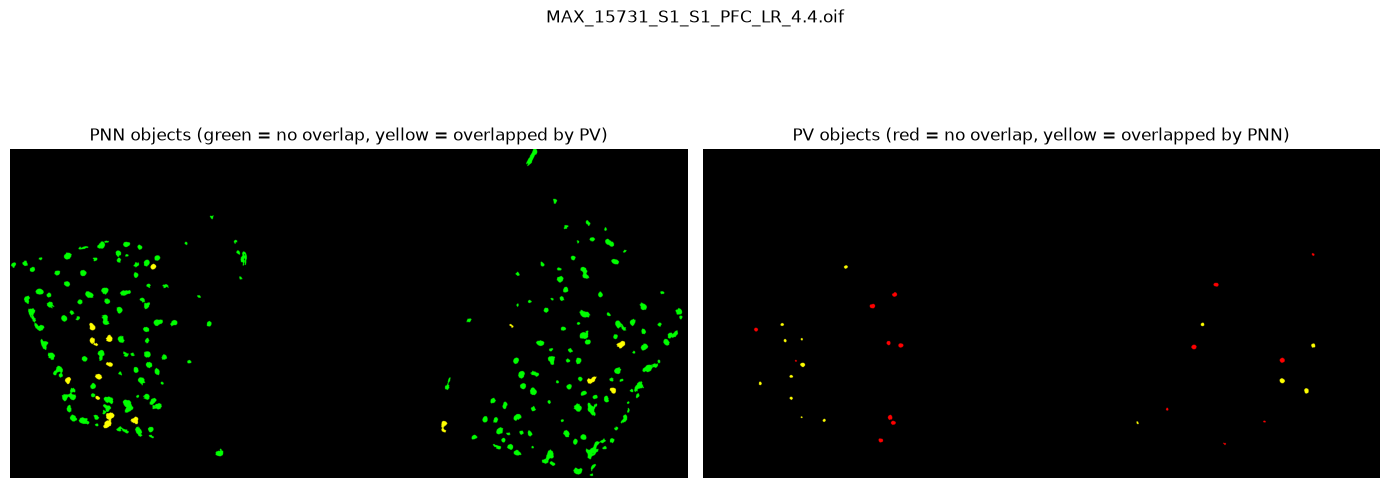

In [64]:
def colour_objects(labels, overlap_px, base_colour):
    """Objects with any overlap are yellow, the rest keep their stain colour."""
    overlapped = np.concatenate([[False], overlap_px > 0])	# index 0 = background
    rgb = np.zeros((*labels.shape, 3), dtype=np.uint8)
    rgb[labels > 0] = base_colour
    rgb[overlapped[labels]] = (255, 255, 0)
    return rgb

check_id = matched_ids[0]
pnn_lab = label_mask(pnn_masks[check_id])
pv_lab = label_mask(pv_masks[check_id])
pnn_tab = object_overlap_table(check_id, "PNN", pnn_lab, pv_masks[check_id], pv_lab[1])
pv_tab = object_overlap_table(check_id, "PV", pv_lab, pnn_masks[check_id], pnn_lab[1])

fig, (ax_pnn, ax_pv) = plt.subplots(1, 2, figsize=(14, 6))
ax_pnn.imshow(colour_objects(pnn_lab[1], pnn_tab["overlap_px"].values, (0, 255, 0)))
ax_pnn.set_title("PNN objects (green = no overlap, yellow = overlapped by PV)")
ax_pv.imshow(colour_objects(pv_lab[1], pv_tab["overlap_px"].values, (255, 0, 0)))
ax_pv.set_title("PV objects (red = no overlap, yellow = overlapped by PNN)")
for ax in (ax_pnn, ax_pv):
    ax.axis("off")
fig.suptitle(check_id)
plt.tight_layout()
plt.show()

### Thresholds

The object tables above are *unthresholded*, so you can change your mind without redoing the work. `summarize_objects` applies the thresholds afterwards, using the values you set in **Run settings** at the top:
- `min_size_px`: ignore small objects (default `0` = no filter)
- `min_frac_overlap`: how much of an object must be covered to count as overlapped (default `0` = any shared pixel)

In [65]:
def summarize_objects(objects, min_size_px=0, min_frac_overlap=0.0):
    """For each section and stain: how many objects are overlapped by the other stain?

    min_size_px      : ignore objects smaller than this (0 = keep everything)
    min_frac_overlap : an object only counts as overlapped if at least this fraction of
                       it is covered. With 0, ANY shared pixel counts.
    """
    kept = objects[objects["size_px"] >= min_size_px].copy()
    kept["overlapped"] = (kept["overlap_px"] > 0) & (kept["frac_overlapped"] >= min_frac_overlap)
    out = (kept.groupby(["section_id", "stain"])
               .agg(n_objects=("object_id", "count"), n_overlapped=("overlapped", "sum"))
               .reset_index())
    out["pct_overlapped"] = 100 * out["n_overlapped"] / out["n_objects"]
    return out

object_summary = summarize_objects(all_objects, min_size_px=min_size_px, min_frac_overlap=min_frac_overlap)
object_summary

,section_id,stain,n_objects,n_overlapped,pct_overlapped
0,MAX_15731_S1_S1_PFC_LR_4.4.oif,PNN,209,15,7.177033
1,MAX_15731_S1_S1_PFC_LR_4.4.oif,PV,31,15,48.387097
2,MAX_15747_S1_S5_PFC_LR_2.8-2.0.oif,PNN,369,278,75.338753
3,MAX_15747_S1_S5_PFC_LR_2.8-2.0.oif,PV,552,305,55.253623
4,MAX_15761_S1_S4_PFC_L_3.1_R_3.oif,PNN,256,92,35.937500
5,MAX_15761_S1_S4_PFC_L_3.1_R_3.oif,PV,165,93,56.363636
6,MAX_15764_S1_S2_PFC_4.0_L.oif,PNN,40,23,57.500000
7,MAX_15764_S1_S2_PFC_4.0_L.oif,PV,90,24,26.666667
8,MAX_16302_S1_S3_PFC_LR_3.6.oif,PNN,302,155,51.324503
9,MAX_16302_S1_S3_PFC_LR_3.6.oif,PV,307,168,54.723127


# Save the results

This last cell writes everything into one new folder, `results/<date>_<time>_<run_name>/`. We **do not copy the original data**. Instead the folder records exactly which input files were used, so someone coming back months later can see what was done:

- `overlap_summary.csv`, `object_overlap_summary.csv` and `object_overlap/`: the results (Methods 1 and 2)
- `overlap_images/`: one overlap picture per section
- `input_manifest.csv`: every input file used, with its location, size, date and a content fingerprint (SHA-256), so you can tell if a file was later changed
- `run_info.json`: the settings, folder paths and software versions
- `notebook_snapshot.ipynb`: a copy of the code that made the results
- `README.txt`: a plain-English guide to the folder and every column

If you run this cell twice in a row it will stop, rather than overwrite. Re-run the **Run settings** cell near the top to start a new folder.

In [66]:
import hashlib, json, platform, shutil, subprocess, sys

notebook_file = Path("overlap_walkthrough.ipynb")

# ---------- Make the run folder ----------
run_dir.mkdir(parents=True, exist_ok=False)		# stops if this folder already exists, so nothing is overwritten
(run_dir / "object_overlap").mkdir()
(run_dir / "overlap_images").mkdir()

# ---------- Results tables ----------
summary.to_csv(run_dir / "overlap_summary.csv", index=False)
object_summary.to_csv(run_dir / "object_overlap_summary.csv", index=False)
for sid, table in all_objects.groupby("section_id"):
    table.to_csv(run_dir / "object_overlap" / f"{sid}_objects.csv", index=False)

# ---------- Overlap pictures (full resolution PNGs) ----------
for sid in matched_ids:
    rgb = overlap_image(pnn_masks[sid], pv_masks[sid])
    cv2.imwrite(str(run_dir / "overlap_images" / f"{sid}_overlap.png"),
                cv2.cvtColor(rgb, cv2.COLOR_RGB2BGR))		# OpenCV saves in BGR order

# ---------- Input manifest: exactly which files this run used ----------
def sha256_of(path):
    """A fingerprint of the file's contents. If the file changes, the fingerprint changes."""
    h = hashlib.sha256()
    with open(path, "rb") as f:
        for chunk in iter(lambda: f.read(1 << 20), b""):
            h.update(chunk)
    return h.hexdigest()

manifest = []
for stain, index in (("PNN", pnn_index), ("PV", pv_index)):
    for sid, path in index.items():
        info = path.stat()
        manifest.append({
            "section_id": sid,
            "stain": stain,
            "used_in_analysis": sid in matched_ids,		# False = no partner file in the other folder
            "file_path": str(path.resolve()),
            "size_bytes": info.st_size,
            "last_modified": datetime.fromtimestamp(info.st_mtime).isoformat(timespec="seconds"),
            "sha256": sha256_of(path),
        })
pd.DataFrame(manifest).sort_values(["section_id", "stain"]).to_csv(run_dir / "input_manifest.csv", index=False)

# ---------- Run info: settings and software versions ----------
def git_commit():
    try:
        return subprocess.run(["git", "rev-parse", "HEAD"], capture_output=True, text=True, check=True).stdout.strip()
    except (subprocess.CalledProcessError, FileNotFoundError):
        return None		# not a git repo, or no commits yet

run_info = {
    "run_name": run_name,
    "run_time": datetime.now().isoformat(timespec="seconds"),
    "pnn_folder": str(pnn_folder.resolve()),
    "pv_folder": str(pv_folder.resolve()),
    "mask_file_ending": mask_suffix,
    "sections_matched": len(matched_ids),
    "sections_only_in_pnn_folder": only_pnn,
    "sections_only_in_pv_folder": only_pv,
    "settings": {
        "object_connectivity": 8,
        "min_size_px": min_size_px,
        "min_frac_overlap": min_frac_overlap,
    },
    "software": {
        "python": sys.version.split()[0],
        "numpy": np.__version__,
        "pandas": pd.__version__,
        "opencv": cv2.__version__,
        "platform": platform.platform(),
    },
    "git_commit": git_commit(),
}
with open(run_dir / "run_info.json", "w") as f:
    json.dump(run_info, f, indent=2)

# ---------- Snapshot of the code that made these results ----------
if notebook_file.exists():
    shutil.copy2(notebook_file, run_dir / "notebook_snapshot.ipynb")

# ---------- README so the folder explains itself ----------
readme = f"""OVERLAP ANALYSIS: {run_name}
Run on {run_info['run_time']}

WHAT THIS IS
Overlap between two Ilastik classification masks (PNN and PV) for each brain section.
Only sections found in BOTH folders were analysed ({len(matched_ids)} sections).

INPUTS (not copied here; see input_manifest.csv for every file and its fingerprint)
  PNN masks: {pnn_folder.resolve()}
  PV masks : {pv_folder.resolve()}
  Mask files used: "<section>_<PNN or PV>_{mask_suffix}"

SETTINGS (Method 2 only)
  Objects were found with 8-connectivity (diagonal pixels count as touching).
  min_size_px      = {min_size_px}   (objects smaller than this were ignored in object_overlap_summary.csv)
  min_frac_overlap = {min_frac_overlap}   (0 = an object counts as overlapped if ANY of it is covered)

FILES
  overlap_summary.csv           Method 1: whole-section overlap, one row per section
  object_overlap_summary.csv    Method 2: how many objects are overlapped, per section and stain
  object_overlap/               Method 2 detail: one CSV per section, one row per object (NOT thresholded)
  overlap_images/               One picture per section: red = PV, green = PNN, yellow = both
  input_manifest.csv            Every input file used, with size, date and SHA-256 fingerprint
  run_info.json                 Settings, software versions and folder paths for this run
  notebook_snapshot.ipynb       Copy of the notebook as last saved on disk when this run finished

METHOD 1 COLUMNS (overlap_summary.csv)
  pct_PNN_covered_by_PV    Of all the PNN-stained area, the % that is also PV-stained
  pct_PV_covered_by_PNN    Of all the PV-stained area, the % that is also PNN-stained
  pct_of_combined_shared   Of the area stained by EITHER, the % stained by BOTH
  PNN_pixels, PV_pixels    Number of stained pixels in each mask
  shared_pixels            Pixels stained in both masks
  combined_pixels          Pixels stained in either mask

METHOD 2 COLUMNS (object_overlap/ files)
  stain                    Which stain this object belongs to (PNN or PV)
  object_id                Number given to the object within its mask (not Ilastik's own ID)
  size_px                  Size of the object in pixels
  centroid_x, centroid_y   Centre of the object in the image (pixels)
  overlap_px               Pixels of this object that are covered by the OTHER stain
  frac_overlapped          overlap_px / size_px (0 = none covered, 1 = fully covered)
  n_partner_objects        How many objects of the OTHER stain touch this object

METHOD 2 COLUMNS (object_overlap_summary.csv)
  n_objects                Objects of this stain kept after the size threshold
  n_overlapped             How many of them are overlapped by the other stain
  pct_overlapped           n_overlapped / n_objects, as a percentage

NOTES
  The two Method 2 directions are not mirror images: a stain's objects are compared
  against the other stain, so PNN and PV can give different percentages.
  Object counts can differ slightly from Ilastik's own tables because objects are
  re-found from the exported mask.
"""
(run_dir / "README.txt").write_text(readme)

print(f"Saved this run to: {run_dir.resolve()}")
for p in sorted(run_dir.rglob("*")):
    if p.is_file():
        print("  ", p.relative_to(run_dir))

Saved this run to: /Users/ben/Documents/source/tara_ilastik_code/results/2026-11-23_1917_PNN-vs-PV
   README.txt
   input_manifest.csv
   notebook_snapshot.ipynb
   object_overlap/MAX_15731_S1_S1_PFC_LR_4.4.oif_objects.csv
   object_overlap/MAX_15747_S1_S5_PFC_LR_2.8-2.0.oif_objects.csv
   object_overlap/MAX_15761_S1_S4_PFC_L_3.1_R_3.oif_objects.csv
   object_overlap/MAX_15764_S1_S2_PFC_4.0_L.oif_objects.csv
   object_overlap/MAX_16302_S1_S3_PFC_LR_3.6.oif_objects.csv
   object_overlap/MAX_16308_S1_S6_PFC_L_2.2_R_2.oif_objects.csv
   object_overlap/MAX_16317_S1_S1_PFC_R_4.4.oif_objects.csv
   object_overlap/MAX_16340_S1_S4_PFC_LR_-3.2.oif_objects.csv
   object_overlap_summary.csv
   overlap_images/MAX_15731_S1_S1_PFC_LR_4.4.oif_overlap.png
   overlap_images/MAX_15747_S1_S5_PFC_LR_2.8-2.0.oif_overlap.png
   overlap_images/MAX_15761_S1_S4_PFC_L_3.1_R_3.oif_overlap.png
   overlap_images/MAX_15764_S1_S2_PFC_4.0_L.oif_overlap.png
   overlap_images/MAX_16302_S1_S3_PFC_LR_3.6.oif_overlap.png
